# Notebook de obtención, limpieza y transformación de datos — Fase 2

**Proyecto:** Análisis de alojamientos Airbnb en Santiago de Chile para la
decisión de inversión inmobiliaria

---

### ¿Qué es un *pipeline* de preprocesamiento?

Un *pipeline* es una secuencia ordenada de pasos por los que pasan los datos
crudos hasta quedar listos para analizar. En este notebook el flujo es:

**Obtener → Anonimizar → Explorar → Limpiar → Filtrar → Transformar → Validar**

Cada paso queda implementado como una **función** reutilizable. Trabajar con
funciones en vez de copiar y pegar código deja el proceso mas ordenado, mas
fácil de corregir, y permite reutilizar la misma lógica sobre cualquier
columna sin reescribirla.

> **Particularidad de este proyecto.** El archivo original trae datos
> personales de anfitriones. Por eso la muestra de `data/raw/` se anonimiza al
> generarla (decisión D5, en `src/generar_muestra.py`): ningún archivo del
> repositorio los contiene. El pipeline **verifica y reaplica la misma regla
> al cargar**, por si el archivo de trabajo llegara a cambiar.

## Introducción

El proyecto describe qué características de ubicación, tipología, capacidad y
servicios presentan los departamentos completos activos en Airbnb Santiago con
mayor ocupación e ingresos estimados. Este cuaderno deja el conjunto de datos
listo para ese análisis.

**Objetivo general (Fase 2).** Construir un *pipeline* reproducible de carga,
anonimización, limpieza y transformación que deje el conjunto de alojamientos
listo para el cálculo de indicadores de la Fase 3.

**Objetivos específicos.**
- Obtener los datos y eliminar la información personal antes de cualquier análisis.
- Explorar el conjunto verificando su estructura y calidad.
- Limpiar: columnas vacías, tipos de datos, valores faltantes e inconsistencias.
- Filtrar el universo de análisis: departamentos completos activos (D1 y D2).
- Transformar: agrupar categorías, binarizar comodidades y derivar variables.
- Validar técnicamente el resultado y persistirlo en `data/processed/`.

**Atributos principales:** `id`, `neighbourhood_cleansed` (comuna),
`property_type`, `room_type`, `accommodates`, `bedrooms`, `beds`,
`bathrooms_text`, `amenities`, `price`, `availability_365`,
`number_of_reviews_ltm`, `estimated_occupancy_l365d`,
`estimated_revenue_l365d` y los puntajes `review_scores_*`.

### Librerías utilizadas

| Librería | Para qué la usamos |
|---|---|
| `numpy` | Cálculo numérico y manejo de arreglos. |
| `pandas` | Cargar y manipular la tabla de datos (el `DataFrame`). |
| `matplotlib` | Sacar los gráficos de control (*boxplots*). |
| `json`, `re`, `datetime` | Biblioteca estándar: comodidades en JSON, extracción de baños y fechas. |
| `src/utilidades.py` | Módulo propio de la Fase 1: `seudonimizar` y la excepción `ProyectoError`. |

`np.random.seed(42)` fija la semilla aleatoria: cualquier proceso con azar da
**siempre el mismo resultado**, que es lo que asegura la *reproducibilidad*
que pide la fase.

In [1]:
import sys                                   # intérprete del kernel
import subprocess                            # instalar paquetes faltantes
import importlib                             # refrescar las importaciones
import importlib.util                        # comprobar si un paquete está instalado

# Revisión del entorno: instala en el kernel lo que haga falta.
REQUERIDOS = {                               # módulo: nombre del paquete en pip
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
}
faltantes = [pkg for mod, pkg in REQUERIDOS.items()
             if importlib.util.find_spec(mod) is None]

if faltantes:
    print("Instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])
    importlib.invalidate_caches()

import json                                  # parseo de la lista de comodidades
import re                                    # extracción del número de baños
import numpy as np                           # cálculo numérico y vectores
import pandas as pd                          # estructuras tabulares: Series y DataFrame
import matplotlib.pyplot as plt              # gráficos de control

# Reproducibilidad: se fija la semilla aleatoria
SEMILLA = 42
np.random.seed(SEMILLA)

# Con 90 columnas de entrada conviene cortar lo que pandas imprime de una vez:
# el cuaderno queda mas liviano y las tablas se siguen leyendo bien.
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 140)

%matplotlib inline

## Configuración del entorno y de las rutas

Antes de cargar nada conviene revisar el entorno y dejar declaradas las rutas.
Trabajamos con rutas **relativas** a la raíz del repositorio, coherentes con la
estructura que dejó la Fase 1: una ruta absoluta tipo `C:/Users/...` solo
funciona en un solo computador del mundo.

In [2]:
from pathlib import Path      # rutas que sirven igual en cualquier sistema

# sys.version trae la versión completa con fecha de compilación;
# split()[0] deja solo el número, que es lo unico que hay que revisar.
print("Python:", sys.version.split()[0])
for lib, mod in [("numpy", np), ("pandas", pd)]:
    print(f"{lib:8}:", mod.__version__)

# Estructura del proyecto. parents=True crea las carpetas del medio;
# exist_ok=True evita el error si ya existen.
def localizar_raiz(inicio=None):
    """
    Devuelve la raíz del proyecto.

    Jupyter abre el kernel en la carpeta donde quedó guardado el cuaderno, no en
    la carpeta desde donde se lanzó JupyterLab. Como cada cuaderno vive en la
    carpeta de su fase (F1, F2, F3 o F4), cuando la carpeta de trabajo es una de
    esas la raíz es la carpeta de arriba. Si el cuaderno corre desde la raíz, se
    usa tal cual.
    """
    inicio = Path.cwd() if inicio is None else Path(inicio)
    return inicio.parent if inicio.name in {"F1", "F2", "F3", "F4"} else inicio


RAIZ = localizar_raiz()                      # la misma función del cuaderno de la Fase 1
DIR_CRUDO = RAIZ / "data" / "raw"            # datos originales: nunca se modifican
DIR_PROCESADO = RAIZ / "data" / "processed"  # resultado del pipeline
DIR_DOCS = RAIZ / "docs"                     # diccionario, bitácora y metadatos
DIR_SRC = RAIZ / "src"                       # módulo propio de la Fase 1
for carpeta in (DIR_CRUDO, DIR_PROCESADO, DIR_DOCS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Se importa el módulo de la Fase 1: la anonimización usa su seudonimizar.
if str(DIR_SRC.resolve()) not in sys.path:
    sys.path.insert(0, str(DIR_SRC.resolve()))
import utilidades

ARCHIVO = DIR_CRUDO / "listings.csv"
print("\nArchivo esperado en:", ARCHIVO.relative_to(RAIZ))

Python: 3.14.4
numpy   : 2.5.4
pandas  : 3.1.1

Archivo esperado en: data/raw/listings.csv


### Procedencia del conjunto de datos

| Campo | Valor |
| --- | --- |
| Título | Inside Airbnb — Santiago, Chile (`listings.csv` detallado) |
| Autor | Inside Airbnb |
| Enlace | `http://insideairbnb.com/get-the-data/` |
| Captura | 25–26 de septiembre de 2026 |
| Archivo de trabajo | Muestra estratificada por comuna, anonimizada: 5.106 filas × 78 columnas (semilla 42) |
| Unidad de observación | Un alojamiento publicado |

**Referencia en APA 7 para el informe:**

> Inside Airbnb. (2026). *Get the data: Santiago, Chile* [Conjunto de datos]. http://insideairbnb.com/get-the-data/

Documentar la procedencia no es un trámite: sin ella nadie puede verificar
sobre que versión del archivo se trabajó.

## 1. Obtención de los datos

**Qué hace este paso.** Lee el archivo CSV y lo carga en un `DataFrame`.

**Por qué con una función.** La lectura quedó encapsulada en
`cargar_datos(ruta)` con un bloque `try / except`. Así, si el archivo no
existe, en vez de un error técnico confuso el usuario recibe un mensaje claro
de qué revisar —en este caso, cómo regenerar la muestra. La función además
imprime las dimensiones cargadas, que sirve de primera verificación de que el
archivo se leyó bien.

In [3]:
def cargar_datos(ruta):
    """
    Carga un conjunto de datos desde un archivo CSV.

    Parametros
    ----------
    ruta : str o Path
        Ruta del archivo CSV.

    Retorna
    -------
    pd.DataFrame
        Datos cargados en un DataFrame.

    Lanza
    -----
    FileNotFoundError
        Si el archivo no existe, con un mensaje que indica cómo generarlo.
    """
    ruta = Path(ruta)
    try:
        df = pd.read_csv(ruta)
    except FileNotFoundError:
        # from None esconde la traza interna de pandas: queda solo el mensaje util.
        try:
            ruta_mostrar = ruta.relative_to(RAIZ)
        except (ValueError, NameError):
            ruta_mostrar = ruta
        raise FileNotFoundError(
            f"No se encontró {ruta_mostrar}.\n"
            "Descargue listings.csv (detallado) desde Inside Airbnb y genere "
            "la muestra con:  python src/generar_muestra.py ruta/al/listings.csv"
        ) from None
    print(f"Datos cargados: {df.shape[0]} filas y {df.shape[1]} columnas.")
    return df


df_crudo = cargar_datos(ARCHIVO)

# El original queda intacto y se trabaja sobre una copia
df = df_crudo.copy()

Datos cargados: 5106 filas y 78 columnas.


## 2. Anonimización: verificar que no queden datos personales (decisión D5)

**Qué hace este paso.** Elimina las columnas con información personal del
anfitrión y del anuncio, y reemplaza `host_id` por un código seudonimizado.

**Dónde se aplica.** La regla ya se ejecutó en `src/generar_muestra.py`, que es
donde nace el archivo de trabajo: la muestra de `data/raw/` llega **ya
anonimizada** y por eso puede versionarse. Esta función reaplica la misma
regla de forma **idempotente** —si el archivo trajera de nuevo esas columnas
las elimina, y si `host_id` viniera numérico lo seudonimiza— y después
**verifica** que el resultado no tenga datos personales. La protección no
depende de confiar en que el archivo llegó bien.

| Columna eliminada en la generación | Qué expone |
| --- | --- |
| `name`, `description` | Pueden incluir nombres, teléfonos o direcciones |
| `host_name`, `host_about`, `host_location` | Identidad del anfitrión |
| `host_url`, `host_profile_id`, `host_profile_url`, `host_picture_url`, `host_thumbnail_url`, `picture_url`, `listing_url` | Enlaces e identificadores de perfiles y fotografías |

`host_id` **no** se elimina: se reemplaza por el código hash de
`utilidades.seudonimizar`, de modo que sigue siendo posible contar cuántos
anuncios tiene un mismo anfitrión sin guardar su identificador.

In [4]:
COLUMNAS_PERSONALES = [
    "name", "description",
    "host_name", "host_about", "host_location",
    "host_url", "host_profile_id", "host_profile_url",
    "host_picture_url", "host_thumbnail_url",
    "picture_url", "listing_url",
]


def eliminar_datos_personales(df, columnas=COLUMNAS_PERSONALES, col_id="host_id"):
    """
    Elimina las columnas con datos personales y seudonimiza el id del
    anfitrion. Es idempotente: la muestra ya llega anonimizada desde
    src/generar_muestra.py, pero si el archivo cambiara la regla se vuelve a
    aplicar.

    Parametros
    ----------
    df : pd.DataFrame
    columnas : list of str
        Columnas a eliminar por contener datos personales.
    col_id : str
        Identificador personal a seudonimizar con hash (solo si aun es numerico).

    Retorna
    -------
    pd.DataFrame
        Copia sin las columnas personales y con col_id seudonimizado.
    """
    df = df.copy()
    presentes = [c for c in columnas if c in df.columns]
    df = df.drop(columns=presentes)
    if col_id in df.columns and df[col_id].astype(str).str.isdigit().all():
        df[col_id] = df[col_id].map(utilidades.seudonimizar)
        estado_id = "seudonimizado en esta ejecución"
    else:
        estado_id = "ya venía seudonimizado"
    print(f"Columnas personales: {len(presentes)} eliminadas ahora, "
          f"{len(columnas) - len(presentes)} ya ausentes del archivo")
    print(f"'{col_id}': {estado_id} -> ejemplo: {df[col_id].iloc[0]}")
    return df


df = eliminar_datos_personales(df)

# Verificación de ida y vuelta: no puede quedar ninguna columna personal en df.
quedan = [c for c in COLUMNAS_PERSONALES if c in df.columns]
assert not quedan, f"Aún quedan columnas personales: {quedan}"
assert not df["host_id"].astype(str).str.isdigit().all(), \
    "host_id debe quedar seudonimizado, no numérico."
print("\n[OK] Sin datos personales en el DataFrame de trabajo")

Columnas personales: 0 eliminadas ahora, 12 ya ausentes del archivo
'host_id': ya venía seudonimizado -> ejemplo: 8a3c202cc613

[OK] Sin datos personales en el DataFrame de trabajo


## 3. Exploración inicial

**Qué hace este paso.** Antes de modificar nada mas, miramos el estado
original de los datos. Es la "línea base" contra la que después se verifica
cada transformación.

La función `explorar_dataframe` reporta cuatro cosas:
1. **Dimensiones** (`shape`): cuántas filas y columnas hay.
2. **Tipos de datos** (`dtypes`): cuántas columnas son numéricas y cuántas texto.
3. **Valores nulos** (`isna().mean()`): qué variables concentran los faltantes.
4. **Estadísticos descriptivos** (`describe()`): rangos de las variables
   numéricas, útil para pillar valores extremos o imposibles.

In [5]:
def explorar_dataframe(df, tope_nulos=15):
    """Resumen exploratorio: dimensiones, tipos, nulos y estadisticos."""
    print("Dimensiones:", df.shape)
    print("\nTipos de datos (conteo por tipo):")
    print(df.dtypes.astype(str).value_counts().to_string())
    print("\nColumnas con mas faltantes (% de nulos):")
    nulos = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
    print(nulos.head(tope_nulos).to_string())
    print(f"\nColumnas 100 % vacías: {int((df.isna().mean() == 1).sum())}")
    print("\nEstadisticos descriptivos de variables clave:")
    return df[["accommodates", "bedrooms", "beds", "minimum_nights",
               "availability_365", "number_of_reviews",
               "number_of_reviews_ltm", "estimated_occupancy_l365d",
               "estimated_revenue_l365d"]].describe()


explorar_dataframe(df)

Dimensiones: (5106, 78)

Tipos de datos (conteo por tipo):
float64    36
int64      22
str        20

Columnas con mas faltantes (% de nulos):
neighborhood_overview           100.0
host_since                      100.0
host_response_time              100.0
host_response_rate              100.0
host_acceptance_rate            100.0
host_neighbourhood              100.0
calendar_updated                100.0
instant_bookable                100.0
neighbourhood_group_cleansed    100.0
bathrooms                       100.0
host_verifications              100.0
neighbourhood                   100.0
host_total_listings_count       100.0
license                          99.0
source                           95.3

Columnas 100 % vacías: 13

Estadisticos descriptivos de variables clave:


,accommodates,bedrooms,beds,minimum_nights,availability_365,number_of_reviews,number_of_reviews_ltm,estimated_occupancy_l365d,estimated_revenue_l365d
count,5106.000000,5104.000000,5052.000000,5106.000000,5106.000000,5106.000000,5106.000000,5106.000000,4.866000e+03
mean,3.153545,1.406740,2.110847,3.367998,279.754798,41.663533,14.530552,77.226596,5.700928e+06
std,1.795065,0.844065,1.751540,16.009862,107.407298,72.124984,20.700096,86.070910,2.047537e+07
min,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
25%,2.000000,1.000000,1.000000,1.000000,247.000000,3.000000,0.000000,0.000000,2.400000e+05
50%,3.000000,1.000000,2.000000,2.000000,335.000000,16.000000,6.000000,42.000000,2.796885e+06
75%,4.000000,2.000000,3.000000,2.000000,358.000000,49.000000,20.000000,126.000000,8.415000e+06
max,16.000000,12.000000,57.000000,365.000000,365.000000,950.000000,246.000000,255.000000,1.333225e+09


También revisamos las **variables que definen el universo de análisis** y
las categóricas principales: cuántos anuncios hay por tipo de alojamiento, por
comuna y por tipo de propiedad.

In [6]:
for col in ["room_type", "property_type"]:
    print(f"{col} ({df[col].nunique()} categorías):")
    print(df[col].value_counts().head(10).to_string())
    print("-" * 50)

print(f"neighbourhood_cleansed: {df['neighbourhood_cleansed'].nunique()} comunas")
print(df["neighbourhood_cleansed"].value_counts().head(8).to_string())
print("\nEstructura del precio (tal como llega):")
print(df["price"].dropna().head(3).to_string())

room_type (4 categorías):
room_type
Entire home/apt    4189
Private room        891
Shared room          15
Hotel room           11
--------------------------------------------------
property_type (53 categorías):
property_type
Entire rental unit             3601
Private room in rental unit     374
Private room in home            226
Entire condo                    221
Entire home                     141
Entire serviced apartment       106
Private room in condo            57
Room in hotel                    50
Private room in guesthouse       47
Entire loft                      45
--------------------------------------------------
neighbourhood_cleansed: 32 comunas
neighbourhood_cleansed
Santiago            1986
Providencia          816
Las Condes           761
Ñuñoa                519
Lo Barnechea         237
Estación Central     120
La Florida           112
Vitacura              94

Estructura del precio (tal como llega):
0    $59,303.00
2    $62,941.00
3    $36,902.40


### El diccionario de variables: declarado vs. observado

En la Fase 1 se declaró el rol analítico de las variables del análisis. Acá se
confronta con lo que el archivo trae de verdad, para **todas las columnas**: el
rol observado se detecta con la misma lógica de `validar_dataset.py` y la tabla
completa queda en `docs/diccionario_variables.csv`.

In [7]:
def clasificar(serie):
    """Devuelve el rol analitico observado de una variable."""
    s = serie.dropna()
    if s.empty:
        return "vacía"
    unicos = s.nunique()
    proporcion = unicos / len(s)
    es_numerica = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)

    if unicos == 2:
        return "binaria"
    if es_numerica:
        es_entera = s.mod(1).eq(0).all()
        if es_entera and proporcion > 0.95 and len(s) > 50:
            return "identificador"
        if es_entera and (unicos <= 20 or proporcion < 0.05):
            return "discreta"
        return "continua"
    # --- texto ---
    if pd.to_datetime(s.head(200), errors="coerce", format="mixed").notna().mean() > 0.9:
        return "fecha"
    if s.astype(str).str.len().mean() > 60:
        return "texto libre"
    if proporcion > 0.95 and len(s) > 50:
        return "identificador"
    return "nominal" if unicos <= 15 else "alta cardinalidad"


# Rol que quedó declarado en la Fase 1 para las variables del análisis.
DECLARADOS = {
    "id": "identificador", "host_id": "identificador",
    "neighbourhood_cleansed": "nominal", "latitude": "continua",
    "longitude": "continua", "property_type": "alta cardinalidad",
    "room_type": "nominal", "accommodates": "discreta", "bedrooms": "discreta",
    "beds": "discreta", "bathrooms_text": "nominal", "amenities": "texto libre",
    "price": "continua", "minimum_nights": "discreta",
    "availability_365": "discreta", "number_of_reviews": "discreta",
    "number_of_reviews_ltm": "discreta", "number_of_reviews_l30d": "discreta",
    "reviews_per_month": "continua", "estimated_occupancy_l365d": "discreta",
    "estimated_revenue_l365d": "continua", "first_review": "fecha",
    "last_review": "fecha", "review_scores_rating": "continua",
    "host_is_superhost": "binaria", "calculated_host_listings_count": "discreta",
}

diccionario = pd.DataFrame({
    "variable": df.columns,
    "rol_declarado": [DECLARADOS.get(c, "") for c in df.columns],
    "rol_observado": [clasificar(df[c]) for c in df.columns],
    "dtype": [str(t) for t in df.dtypes],
    "n_unicos": [df[c].nunique() for c in df.columns],
    "pct_nulos": (df.isna().mean() * 100).round(1).values,
})

diccionario.to_csv(DIR_DOCS / "diccionario_variables.csv", index=False)
print(f"Diccionario completo guardado ({len(diccionario)} variables).\n")
print(diccionario["rol_observado"].value_counts().to_string())
diccionario[diccionario["rol_declarado"] != ""].head(12)

Diccionario completo guardado (78 variables).

rol_observado
discreta             27
continua             17
vacía                13
alta cardinalidad     6
binaria               5
fecha                 4
nominal               3
texto libre           2
identificador         1


,variable,rol_declarado,rol_observado,dtype,n_unicos,pct_nulos
0,id,identificador,identificador,int64,5106,0.0
5,host_id,identificador,alta cardinalidad,str,3609,0.0
14,host_is_superhost,binaria,binaria,str,2,0.0
22,neighbourhood_cleansed,nominal,alta cardinalidad,str,32,0.0
24,latitude,continua,continua,float64,4200,0.0
25,longitude,continua,continua,float64,4264,0.0
26,property_type,alta cardinalidad,alta cardinalidad,str,53,0.0
27,room_type,nominal,nominal,str,4,0.0
28,accommodates,discreta,discreta,int64,16,0.0
30,bathrooms_text,nominal,alta cardinalidad,str,28,0.1


## 4. Limpieza de datos

Cuatro problemas concretos, cada uno resuelto con una función justificada:

**a) Columnas vacías.** 14 columnas llegan 100 % nulas (`bathrooms`,
`host_since`, `neighbourhood`, `instant_bookable`, entre otras): no tienen
información y se eliminan. `license` (99 % nulos) y `source` (95 %) tampoco se
recuperan y salen en la misma operación.

**b) El precio es texto.** `price` llega como `"$59,303.00"`: hay que quitarle
el signo peso y el separador de miles antes de cualquier cálculo.

**c) Los baños son texto.** `bathrooms` está vacía y `bathrooms_text` llega
como `"1 bath"`, `"1.5 shared baths"` o `"Half-bath"`: toca extraer el número
y si es compartido.

**d) Faltantes e inconsistencias.** Revisar `beds`, `bedrooms` y el mismo
`price` una vez definido el universo de análisis.

### a) Columnas sin información

Se eliminan las columnas 100 % vacías y las que pasan del 90 % de faltantes:
por encima de ese umbral ya no son recuperables, como quedó declarado en la
evaluación de la Fase 1.

In [8]:
def eliminar_columnas_sin_informacion(df, umbral=0.9):
    """
    Elimina las columnas con % de nulos mayor o igual al umbral.

    Devuelve el DataFrame resultante e imprime la evidencia de cada descarte.
    """
    df = df.copy()
    pct = df.isna().mean()
    a_eliminar = pct[pct >= umbral].index.tolist()
    df = df.drop(columns=a_eliminar)
    for col in a_eliminar:
        print(f"  eliminada {col:<28} nulos: {pct[col] * 100:5.1f} %")
    print(f"\n{len(a_eliminar)} columnas eliminadas. Forma actual: {df.shape}")
    return df


df = eliminar_columnas_sin_informacion(df, umbral=0.9)

  eliminada source                       nulos:  95.3 %
  eliminada neighborhood_overview        nulos: 100.0 %
  eliminada host_since                   nulos: 100.0 %
  eliminada host_response_time           nulos: 100.0 %
  eliminada host_response_rate           nulos: 100.0 %
  eliminada host_acceptance_rate         nulos: 100.0 %
  eliminada host_neighbourhood           nulos: 100.0 %
  eliminada host_total_listings_count    nulos: 100.0 %
  eliminada host_verifications           nulos: 100.0 %
  eliminada neighbourhood                nulos: 100.0 %
  eliminada neighbourhood_group_cleansed nulos: 100.0 %
  eliminada bathrooms                    nulos: 100.0 %
  eliminada calendar_updated             nulos: 100.0 %
  eliminada license                      nulos:  99.0 %
  eliminada instant_bookable             nulos: 100.0 %

15 columnas eliminadas. Forma actual: (5106, 63)


### b) `price`: de texto a número

El precio por noche es la segunda métrica de desempeño del proyecto. Llega
como texto con signo peso y separador de miles (`"$59,303.00"`). La función
`limpiar_precio` recibe un solo valor —así se puede probar de forma aislada— y
después se aplica a toda la columna con `.map()`.

In [9]:
def limpiar_precio(valor):
    """
    Convierte un precio en formato texto monetario a float.

    Ejemplos
    --------
    '$59,303.00' -> 59303.0
    '$1,234.50'  -> 1234.5
    None o texto vacio -> NaN (el faltante se decide aparte)

    Lanza
    -----
    ValueError
        Si el texto no tiene el formato esperado.
    """
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return np.nan
    if isinstance(valor, (int, float)):
        return float(valor)
    texto = str(valor).strip().replace("$", "").replace(",", "")
    if texto == "":
        return np.nan
    try:
        return float(texto)
    except ValueError:
        raise ValueError(f"Formato de precio no reconocido: {valor!r}")


# Casos de prueba antes de aplicarla a las 5.106 filas.
assert limpiar_precio("$59,303.00") == 59303.0
assert limpiar_precio("$1,234.50") == 1234.5
assert np.isnan(limpiar_precio(None)) and np.isnan(limpiar_precio(""))
print("[OK] limpiar_precio pasa los casos de prueba\n")

df["price_clp"] = df["price"].map(limpiar_precio)
print(f"price_clp: {df['price_clp'].isna().sum()} nulos "
      f"({df['price_clp'].isna().mean() * 100:.1f} %), "
      f"mediana {df['price_clp'].median():,.0f} CLP")
df[["price", "price_clp"]].dropna().head(4)

[OK] limpiar_precio pasa los casos de prueba

price_clp: 240 nulos (4.7 %), mediana 55,111 CLP


,price,price_clp
0,"$59,303.00",59303.0
2,"$62,941.00",62941.0
3,"$36,902.40",36902.4
4,"$109,149.50",109149.5


### c) `bathrooms_text`: número y tipo de baño

El texto mezcla dos informaciones: **cuántos** baños (`1`, `1.5`, `Half-bath`
= 0.5) y **de qué tipo** (`shared` = compartido; el resto se toma como
privado). Se sacan en dos columnas porque responden cosas distintas en la
pregunta 2 (configuración del departamento).

In [10]:
def extraer_banos(texto):
    """
    Extrae (numero, compartido) de bathrooms_text.

    Ejemplos
    --------
    '1 bath'           -> (1.0, False)
    '1.5 shared baths' -> (1.5, True)
    'Half-bath'        -> (0.5, False)
    'Shared half-bath' -> (0.5, True)

    Lanza
    -----
    ValueError
        Si el texto no describe baños reconocibles.
    """
    if texto is None or (isinstance(texto, float) and np.isnan(texto)):
        return np.nan, np.nan
    t = str(texto).strip().lower()
    if "bath" not in t:
        raise ValueError(f"Texto de baños no reconocido: {texto!r}")

    compartido = "shared" in t
    if "half" in t and not re.search(r"\d", t):
        numero = 0.5                       # 'Half-bath' no trae dígito
    else:
        encontrado = re.search(r"(\d+\.?\d*)", t)
        numero = float(encontrado.group(1)) if encontrado else np.nan
    return numero, compartido


# Casos de prueba.
assert extraer_banos("1 bath") == (1.0, False)
assert extraer_banos("1.5 shared baths") == (1.5, True)
assert extraer_banos("Half-bath") == (0.5, False)
assert extraer_banos("2 private baths") == (2.0, False)
print("[OK] extraer_banos pasa los casos de prueba\n")

# .map con una función que devuelve tupla da una columna de tuplas; se desempaqueta.
banos = df["bathrooms_text"].map(extraer_banos)
df["banos_numero"] = banos.map(lambda t: t[0])
df["banos_compartidos"] = banos.map(lambda t: t[1])

print(df["bathrooms_text"].value_counts().head(8).to_string())
print(f"\nbanos_numero nulos: {df['banos_numero'].isna().sum()} "
      f"· compartidos: {int(df['banos_compartidos'].sum())}")

[OK] extraer_banos pasa los casos de prueba

bathrooms_text
1 bath            3032
2 baths           1003
1 private bath     392
1 shared bath      238
1.5 baths          100
3 baths             88
2 shared baths      42
2.5 baths           39

banos_numero nulos: 6 · compartidos: 351


### d) Valores atípicos: medir antes de decidir

Antes de filtrar el universo conviene mirar los extremos de las variables de
configuración y del precio. Se usa el criterio del rango intercuartílico:

$$\text{atípico si} \quad x < Q_1 - 1{,}5 \cdot \text{RIC} \quad \text{o} \quad x > Q_3 + 1{,}5 \cdot \text{RIC}$$

In [11]:
def detectar_atipicos_iqr(serie, factor=1.5):
    """Identifica valores atípicos por el criterio del rango intercuartílico.

    Retorna
    -------
    tuple(np.ndarray, float, float)
        Máscara booleana de atípicos, límite inferior y límite superior.
    """
    valores = serie.dropna().to_numpy(dtype="float64")
    q1, q3 = np.percentile(valores, [25, 75])
    ric = q3 - q1
    limite_inf, limite_sup = q1 - factor * ric, q3 + factor * ric
    mascara = (serie < limite_inf) | (serie > limite_sup)
    return mascara.fillna(False).to_numpy(), limite_inf, limite_sup


filas = []
for col in ["price_clp", "bedrooms", "beds", "accommodates", "minimum_nights"]:
    mascara, inf, sup = detectar_atipicos_iqr(df[col])
    filas.append({
        "variable": col,
        "limite_sup": round(sup, 1),
        "máx_observado": round(df[col].max(), 1),
        "n_atipicos": int(mascara.sum()),
        "pct_atipicos": round(mascara.mean() * 100, 2),
        "mediana": round(df[col].median(), 1),
    })
pd.DataFrame(filas)

,variable,limite_sup,máx_observado,n_atipicos,pct_atipicos,mediana
0,price_clp,148672.8,37034021.5,424,8.30,55111.0
1,bedrooms,3.5,12.0,146,2.86,1.0
2,beds,6.0,57.0,127,2.49,2.0
3,accommodates,7.0,16.0,163,3.19,3.0
4,minimum_nights,3.5,365.0,485,9.50,2.0


> **Decisión: los extremos se conservan.** Los valores altos de `beds`
> (hasta 57) o `bedrooms` son raros pero no imposibles —corresponden a casas
> grandes y hostales— y en su mayoría van a quedar por fuera del universo de
> análisis (departamentos completos activos). El precio tiene cola larga de
> verdad: existen alojamientos de lujo. Para el análisis descriptivo de la
> Fase 3 se van a usar **mediana y cuartiles**, que aguantan esta asimetría;
> borrar datos legítimos sería peor decisión que soportarlos con estadísticos
> adecuados. Queda declarado en el registro de decisiones.

## 5. Filtro del universo de análisis (decisiones D1 y D2)

Ahora sí se reduce el conjunto a lo que declara la pregunta de investigación:

- **D1 — departamento o casa completa:** `room_type == "Entire home/apt"`. Las
  piezas privadas, compartidas y los hoteles no corresponden a la compra de un
  departamento.
- **D2 — alojamiento activo:** al menos una reseña en los últimos 12 meses
  (`number_of_reviews_ltm > 0`) y disponibilidad futura (`availability_365 > 0`).
  Un anuncio sin actividad reciente no dice nada del mercado actual.

In [12]:
def filtrar_universo(df):
    """
    Filtra el universo de análisis: vivienda completa y alojamiento activo.

    Decisiones D1 y D2 del registro. Imprime la evidencia de cada corte.
    """
    n0 = len(df)
    es_completa = df["room_type"] == "Entire home/apt"
    es_activo = (df["number_of_reviews_ltm"] > 0) & (df["availability_365"] > 0)

    print(f"Registros de partida                    : {n0}")
    print(f"Entire home/apt (D1)                    : {int(es_completa.sum())} "
          f"({es_completa.mean() * 100:.1f} %)")
    print(f"Activos (D2)                            : {int(es_activo.sum())} "
          f"({es_activo.mean() * 100:.1f} %)")

    resultado = df[es_completa & es_activo].copy()
    print(f"Universo final (D1 ∩ D2)                : {len(resultado)} "
          f"({len(resultado) / n0 * 100:.1f} % del total)")
    return resultado


df = filtrar_universo(df)

Registros de partida                    : 5106
Entire home/apt (D1)                    : 4189 (82.0 %)
Activos (D2)                            : 3734 (73.1 %)
Universo final (D1 ∩ D2)                : 3343 (65.5 % del total)


### Valores faltantes dentro del universo

Con el universo ya definido se miran los faltantes **que quedan**: no es lo
mismo decidir sobre el 4,7 % de precios nulos del archivo completo que sobre
lo que efectivamente se va a analizar.

In [13]:
nulos_universo = df.isna().sum()
print("Nulos restantes en el universo de análisis:")
print(nulos_universo[nulos_universo > 0].sort_values(ascending=False)
      .head(12).to_string())

Nulos restantes en el universo de análisis:
beds                           32
price                          30
price_clp                      30
price_quote_total_price        30
estimated_revenue_l365d        30
price_quote_price_per_night    30
price_quote_checkout_date      15
price_quote_checkin_date       15
price_quote_raw                15
bedrooms                        1


**Decisión sobre `price_clp`.** Las filas sin precio no se pueden evaluar
con la segunda métrica de desempeño, e imputarles un precio inventado a la
variable que se quiere describir sería fabricar el dato. Se eliminan: son una
fracción pequeña del universo.

**Decisión sobre `beds` y `bedrooms`.** Son variables de configuración
(pregunta 2): ahí si conviene imputar. Se compara el efecto de las estrategias
candidatas antes de elegir.

In [14]:
def comparar_imputaciones(datos, columna, agrupador=None, n_grupos=4):
    """Compara el efecto de cuatro estrategias de imputación sobre una variable.

    Retorna
    -------
    pd.DataFrame con el efecto de cada estrategia sobre la distribución.
    """
    original = datos[columna]
    if original.isna().sum() == 0:
        raise ValueError(f"'{columna}' no tiene valores faltantes.")

    resultados = {
        "sin imputar (referencia)": original.dropna(),
        "eliminar filas": original.dropna(),
        "media": original.fillna(original.mean()),
        "mediana": original.fillna(original.median()),
    }
    if agrupador is not None:
        # qcut corta en tramos con la MISMA cantidad de casos;
        # transform("median") deja la mediana del grupo en cada fila.
        tramos = pd.qcut(datos[agrupador], q=n_grupos, duplicates="drop")
        resultados["mediana por grupo"] = original.fillna(
            original.groupby(tramos, observed=True).transform("median"))

    filas = [{
        "estrategia": nombre,
        "n": len(serie.dropna()),
        "media": round(serie.mean(), 3),
        "desv_est": round(serie.std(), 3),
        "asimetria": round(serie.skew(), 3),
    } for nombre, serie in resultados.items()]

    tabla = pd.DataFrame(filas)
    referencia = tabla.iloc[0]["desv_est"]
    tabla["cambio_desv_%"] = ((tabla["desv_est"] - referencia) / referencia * 100).round(2)
    tabla["filas_perdidas"] = len(datos) - tabla["n"]
    return tabla


comparar_imputaciones(df, "beds", agrupador="accommodates")

,estrategia,n,media,desv_est,asimetria,cambio_desv_%,filas_perdidas
0,sin imputar (referencia),3311,2.220,1.572,2.448,0.00,32
1,eliminar filas,3311,2.220,1.572,2.448,0.00,32
2,media,3343,2.220,1.565,2.460,-0.45,0
3,mediana,3343,2.218,1.565,2.463,-0.45,0
4,mediana por grupo,3343,2.218,1.569,2.443,-0.19,0


**Cómo se lee.** `cambio_desv_%` es la columna que decide: toda imputación
por un valor central concentra los datos y **baja artificialmente la
desviación estándar**. La mediana por grupo de capacidad (`accommodates`)
deforma menos porque respeta que un estudio y un departamento de tres
dormitorios no tienen las mismas camas. Se aplica esa estrategia a `beds` y
`bedrooms`, con bandera de imputación para no perder la trazabilidad.

In [15]:
def imputar_mediana_por_grupo(df, columna, agrupador, n_grupos=4):
    """
    Imputa los nulos de una columna con la mediana de su tramo de agrupador.

    Agrega ademas una bandera '<columna>_imputado' (1 = valor imputado) para
    no perder la trazabilidad de qué celdas se rellenaron.
    """
    if columna not in df.columns:
        raise KeyError(f"La columna '{columna}' no existe en el DataFrame.")
    n_nulos = int(df[columna].isna().sum())
    df = df.copy()
    tramos = pd.qcut(df[agrupador], q=n_grupos, duplicates="drop")
    medianas = df[columna].groupby(tramos, observed=True).transform("median")
    # Si un tramo entero fuera NaN, la mediana global cubre el hueco.
    medianas = medianas.fillna(df[columna].median())
    df[f"{columna}_imputado"] = df[columna].isna().astype(int)
    df[columna] = df[columna].fillna(medianas)
    print(f"'{columna}': {n_nulos} nulos imputados con la mediana por tramo "
          f"de '{agrupador}'")
    return df


n_antes = len(df)
df = df.dropna(subset=["price_clp"])
print(f"Filas sin precio eliminadas: {n_antes - len(df)} "
      f"({(n_antes - len(df)) / n_antes * 100:.2f} % del universo)\n")

df = imputar_mediana_por_grupo(df, "beds", "accommodates")
df = imputar_mediana_por_grupo(df, "bedrooms", "accommodates")

Filas sin precio eliminadas: 30 (0.90 % del universo)

'beds': 32 nulos imputados con la mediana por tramo de 'accommodates'
'bedrooms': 1 nulos imputados con la mediana por tramo de 'accommodates'


> **Atención — coherencia de la decisión.** Eliminar filas por `price` e
> imputar `beds` no se contradicen: el precio es una **variable de resultado**
> (se describe, no se fabrica) mientras que camas y dormitorios son
> **características** cuyo faltante es aleatorio y escaso. También se verifica
> `reviews_per_month` (nula por definición cuando no hay reseñas históricas):
> en el universo activo todas las filas tienen reseña reciente, así que solo
> podría faltar por inconsistencia.

In [16]:
# Comprobación de mitad de camino: nulos y duplicados en las columnas del análisis.
CLAVE = ["id", "neighbourhood_cleansed", "room_type", "accommodates",
         "bedrooms", "beds", "banos_numero", "price_clp",
         "estimated_occupancy_l365d", "estimated_revenue_l365d"]

print("Nulos en columnas clave:")
print(df[CLAVE].isna().sum().to_string())

dup_id = int(df["id"].duplicated().sum())
dup_exactos = int(df.duplicated().sum())
print(f"\nid duplicados: {dup_id} · filas duplicadas exactas: {dup_exactos}")
assert dup_id == 0, "Hay alojamientos repetidos por id."

Nulos en columnas clave:
id                           0
neighbourhood_cleansed       0
room_type                    0
accommodates                 0
bedrooms                     0
beds                         0
banos_numero                 0
price_clp                    0
estimated_occupancy_l365d    0
estimated_revenue_l365d      0

id duplicados: 0 · filas duplicadas exactas: 0


## 6. Transformación

Tres transformaciones, cada una al servicio de una pregunta operativa:

**a) `property_type` → `propiedad_agrupada`** (pregunta 2). En el universo hay
18 tipos de propiedad, pero uno solo concentra la gran mayoría. Las categorías
raras se agrupan en `"Otro"` para que los indicadores de la Fase 3 no anden
comparando grupos de tres casos.

**b) `amenities` → variables binarias** (pregunta 3). La lista JSON se parsea y
las comodidades más frecuentes pasan a columnas 0/1, más un conteo total por
alojamiento.

**c) Variables derivadas.** Precio por huésped, bandera del tope de ocupación,
antigüedad del anuncio y bandera de multianfitrión.

In [17]:
def agrupar_property_type(df, columna="property_type", n_top=5,
                          nueva="propiedad_agrupada"):
    """
    Conserva las n_top categorias mas frecuentes y agrupa el resto en 'Otro'.

    Retorna el DataFrame con la nueva columna y la tabla de frecuencias
    resultante.
    """
    frecuencias = df[columna].value_counts()
    top = frecuencias.head(n_top).index.tolist()
    df = df.copy()
    df[nueva] = df[columna].where(df[columna].isin(top), "Otro")
    print(f"Categorías conservadas: {top}")
    print(df[nueva].value_counts().to_string())
    return df


df = agrupar_property_type(df, n_top=5)

Categorías conservadas: ['Entire rental unit', 'Entire condo', 'Entire serviced apartment', 'Entire home', 'Entire loft']
propiedad_agrupada
Entire rental unit           2926
Entire condo                  168
Entire serviced apartment      76
Entire home                    66
Otro                           47
Entire loft                    30


### b) Comodidades: de lista JSON a columnas binarias

`amenities` llega como texto JSON (`["Microwave", "Oven", ...]`) con **1.793
valores distintos** en la muestra —incluye variantes como `"TV"` y `"TV with
standard cable"`. Para la pregunta 3 (comodidades del cuartil superior de
ocupación) no hacen falta todas: se binarizan las mas frecuentes del universo
y se conserva además el conteo total por alojamiento, que resume el nivel de
equipamiento.

In [18]:
def parsear_amenidades(valor):
    """
    Convierte el texto JSON de amenities en una lista de strings.

    '["Wifi", "Kitchen"]' -> ['Wifi', 'Kitchen']
    '[]', None o JSON inválido -> []

    Lanza
    -----
    ValueError
        Si el JSON no es una lista.
    """
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return []
    try:
        lista = json.loads(valor)
    except json.JSONDecodeError:
        return []
    if not isinstance(lista, list):
        raise ValueError(f"amenities no es una lista: {valor!r}")
    return lista


# Casos de prueba antes de procesar las filas del universo.
assert parsear_amenidades('["Wifi", "Kitchen"]') == ["Wifi", "Kitchen"]
assert parsear_amenidades("[]") == [] and parsear_amenidades(None) == []
print("[OK] parsear_amenidades pasa los casos de prueba\n")

listas = df["amenities"].map(parsear_amenidades)
df["amenities_count"] = listas.map(len)

# Frecuencia de cada comodidad en el universo: con eso se decide qué columnas crear.
frecuencia = (pd.Series([a for lista in listas for a in lista])
              .value_counts())
TOP_AMENITIES = 20
principales = frecuencia.head(TOP_AMENITIES)
print(f"Comodidades distintas en el universo: {len(frecuencia)}")
print(f"Se binarizan las {TOP_AMENITIES} más frecuentes:")
print(principales.to_string())

[OK] parsear_amenidades pasa los casos de prueba

Comodidades distintas en el universo: 1504
Se binarizan las 20 más frecuentes:
Kitchen                       3213
Wifi                          3061
Hot water                     2925
Hair dryer                    2765
Cooking basics                2694
Dishes and silverware         2632
Hangers                       2548
Bed linens                    2544
TV                            2524
Microwave                     2522
Self check-in                 2435
Refrigerator                  2416
Iron                          2360
Hot water kettle              2336
Wine glasses                  2212
Elevator                      2189
Extra pillows and blankets    1924
Long term stays allowed       1847
Oven                          1842
Toaster                       1842


In [19]:
# Una columna binaria por comodidad principal. El nombre se normaliza a
# minúsculas con guion bajo usando la función del módulo de la Fase 1.
for amenidad in principales.index:
    columna = "amen_" + utilidades.normalizar_nombre(amenidad)
    df[columna] = listas.map(lambda lista, a=amenidad: int(a in lista))

cols_amen = ["amen_" + utilidades.normalizar_nombre(a) for a in principales.index]
print(f"{len(cols_amen)} columnas binarias creadas:")
print(cols_amen)
print(f"\namenities_count: mediana {df['amenities_count'].median():.0f} "
      f"comodidades por alojamiento")

20 columnas binarias creadas:
['amen_kitchen', 'amen_wifi', 'amen_hot_water', 'amen_hair_dryer', 'amen_cooking_basics', 'amen_dishes_and_silverware', 'amen_hangers', 'amen_bed_linens', 'amen_tv', 'amen_microwave', 'amen_self_check_in', 'amen_refrigerator', 'amen_iron', 'amen_hot_water_kettle', 'amen_wine_glasses', 'amen_elevator', 'amen_extra_pillows_and_blankets', 'amen_long_term_stays_allowed', 'amen_oven', 'amen_toaster']

amenities_count: mediana 36 comodidades por alojamiento


### c) Variables derivadas

| Variable | Definición | Para qué |
| --- | --- | --- |
| `precio_por_huesped` | `price_clp / accommodates` | Comparar precios entre configuraciones distintas |
| `ocupacion_tope` | `estimated_occupancy_l365d == 255` | Marca los alojamientos en el tope declarado como sesgo |
| `antiguedad_dias` | `last_scraped − first_review` | Años de trayectoria del anuncio |
| `es_multianfitrion` | `calculated_host_listings_count > 1` | Distingue operadores con varios anuncios |

In [20]:
df["precio_por_huesped"] = df["price_clp"] / df["accommodates"]
df["ocupacion_tope"] = (df["estimated_occupancy_l365d"] == 255).astype(int)

# last_scraped es la fecha de captura (25-26 sep. 2026): la diferencia con la
# primera reseña aproxima la antigüedad del anuncio en la plataforma.
fecha_captura = pd.to_datetime(df["last_scraped"])
primera_resena = pd.to_datetime(df["first_review"], errors="coerce")
df["antiguedad_dias"] = (fecha_captura - primera_resena).dt.days

df["es_multianfitrion"] = (df["calculated_host_listings_count"] > 1).astype(int)

print(f"En el tope de ocupación (255 noches): {int(df['ocupacion_tope'].sum())} "
      f"({df['ocupacion_tope'].mean() * 100:.1f} %)")
print(f"Multianfitrión (>1 anuncio): {int(df['es_multianfitrion'].sum())} "
      f"({df['es_multianfitrion'].mean() * 100:.1f} %)")
print(f"Antigüedad mediana: {df['antiguedad_dias'].median() / 365:.1f} años")
print(f"Precio por huésped: mediana {df['precio_por_huesped'].median():,.0f} CLP")

En el tope de ocupación (255 noches): 439 (13.3 %)
Multianfitrión (>1 anuncio): 2140 (64.6 %)
Antigüedad mediana: 1.3 años
Precio por huésped: mediana 20,750 CLP


### ¿Y el escalamiento?

**No se aplica, y eso también es una decisión.** La estandarización
(*z-score*) se justifica cuando los datos alimentan modelos basados en
distancia (KNN, SVM, regresión regularizada). Este proyecto es **descriptivo**:
la Fase 3 calcula medianas, cuartiles y tasas por grupo, que no dependen de la
escala. Escalar acá metería un paso sin propósito y complicaría leer los
indicadores en unidades reales (CLP, noches). Si una fase posterior lo
necesita, se aplica dentro del flujo de esa fase.

### Selección de columnas finales

De las columnas que quedan se conservan las que alimentan el análisis y la
trazabilidad. Las auxiliares ya cumplieron su función (`amenities` original,
`bathrooms_text`, `price` en texto) y las vacías o irrelevantes para las
preguntas se descartan.

In [21]:
COLUMNAS_FINALES = (
    ["id", "host_id", "neighbourhood_cleansed", "latitude", "longitude",
     "property_type", "propiedad_agrupada", "room_type",
     "accommodates", "bedrooms", "bedrooms_imputado", "beds", "beds_imputado",
     "banos_numero", "banos_compartidos", "amenities_count"]
    + cols_amen
    + ["price_clp", "precio_por_huesped", "minimum_nights", "maximum_nights",
       "availability_30", "availability_60", "availability_90", "availability_365",
       "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d",
       "reviews_per_month", "estimated_occupancy_l365d",
       "estimated_revenue_l365d", "ocupacion_tope",
       "first_review", "last_review", "antiguedad_dias",
       "review_scores_rating", "review_scores_accuracy",
       "review_scores_cleanliness", "review_scores_checkin",
       "review_scores_communication", "review_scores_location",
       "review_scores_value", "host_is_superhost",
       "calculated_host_listings_count", "es_multianfitrion"]
)

# Verificación previa: no puede faltar ninguna de las columnas pedidas.
faltantes = [c for c in COLUMNAS_FINALES if c not in df.columns]
assert not faltantes, f"Columnas finales ausentes: {faltantes}"

df = df[COLUMNAS_FINALES].copy()
print(f"Conjunto final: {df.shape[0]} filas x {df.shape[1]} columnas")

Conjunto final: 3313 filas x 64 columnas


## 7. Validación técnica y verificación del código

Verificar es demostrar, con evidencia, que el resultado es correcto. La
función `validar_dataset` ejecuta las comprobaciones del proyecto y usa
`assert`: si algo no se cumple, el notebook se frena con un error y queda
constancia de la falla.

Se comprueba:
1. **Universo** — todas las filas son `Entire home/apt` y activas (D1, D2).
2. **Integridad** — sin nulos en las columnas clave del análisis.
3. **Rangos** — precio y baños no negativos, ocupación dentro de [0, 255].
4. **Comodidades** — las columnas binarias solo traen 0 y 1.
5. **Identificadores** — `id` único; `host_id` seudonimizado (no numérico).
6. **Dimensiones** — la forma final de la tabla.

In [22]:
def validar_dataset(df, cols_amen):
    """
    Comprueba universo, integridad, rangos y coherencia del dataset final.
    Lanza AssertionError si alguna comprobacion falla.
    """
    print("VALIDACION DEL DATASET FINAL")
    print("-" * 45)

    # 1. Universo de análisis (D1 y D2)
    assert (df["room_type"] == "Entire home/apt").all(), "Quedan room_type no deseados."
    assert (df["number_of_reviews_ltm"] > 0).all(), "Quedan alojamientos sin reseña reciente."
    assert (df["availability_365"] > 0).all(), "Quedan alojamientos sin disponibilidad."
    print("[OK] Universo: solo departamentos completos activos")

    # 2. Integridad en columnas clave
    clave = ["id", "neighbourhood_cleansed", "price_clp", "accommodates",
             "estimated_occupancy_l365d", "banos_numero"]
    nulos = {c: int(df[c].isna().sum()) for c in clave}
    nulos = {c: n for c, n in nulos.items() if n > 0}
    assert not nulos, f"Nulos en columnas clave: {nulos}"
    print("[OK] Sin valores nulos en columnas clave")

    # 3. Rangos que tengan sentido
    assert (df["price_clp"] > 0).all(), "Hay precios nulos o no positivos."
    assert df["estimated_occupancy_l365d"].between(0, 255).all(), \
        "Ocupación fuera del rango [0, 255]."
    assert (df["banos_numero"] >= 0).all(), "Baños negativos."
    assert (df["accommodates"] >= 1).all(), "Capacidad menor a 1."
    print("[OK] Rangos válidos (precio > 0, ocupación ≤ 255, baños y capacidad ≥ 0)")

    # 4. Columnas de comodidades binarias
    for col in cols_amen:
        assert df[col].isin([0, 1]).all(), f"{col} tiene valores no binarios."
    print(f"[OK] {len(cols_amen)} columnas de comodidades son binarias")

    # 5. Identificadores
    assert df["id"].is_unique, "id tiene valores repetidos."
    assert not df["host_id"].astype(str).str.isdigit().all(), \
        "host_id no quedó seudonimizado."
    print("[OK] id único y host_id seudonimizado")

    # 6. Dimensiones finales
    dup = int(df.duplicated().sum())
    print(f"[INFO] Filas duplicadas: {dup}")
    print(f"[INFO] Dimensiones finales: {df.shape}")
    return True


validar_dataset(df, cols_amen)

VALIDACION DEL DATASET FINAL
---------------------------------------------
[OK] Universo: solo departamentos completos activos
[OK] Sin valores nulos en columnas clave
[OK] Rangos válidos (precio > 0, ocupación ≤ 255, baños y capacidad ≥ 0)
[OK] 20 columnas de comodidades son binarias
[OK] id único y host_id seudonimizado
[INFO] Filas duplicadas: 0
[INFO] Dimensiones finales: (3313, 64)


True

### Pruebas de las funciones (casos normal, límite y excepciones)

Además de validar el *dataset*, probamos las funciones del pipeline en tres
escenarios, como pide la rúbrica. Las funciones ya pasaron sus casos normales
al aplicarse; acá se fuerzan los casos límite y las excepciones.

In [23]:
# --- Caso limite: textos de baño poco frecuentes pero reales ---
assert extraer_banos("Shared half-bath") == (0.5, True)
assert extraer_banos("0 baths") == (0.0, False)
assert limpiar_precio("$0.00") == 0.0
print("[OK] Casos límite: medio baño compartido, cero baños y precio cero")

# --- Excepcion 1: precio con formato irreconocible ---
try:
    limpiar_precio("sesenta mil")
except ValueError as e:
    print(f"[OK] Excepción capturada (precio): {e}")

# --- Excepcion 2: texto de baños que no habla de baños ---
try:
    extraer_banos("no aplica")
except ValueError as e:
    print(f"[OK] Excepción capturada (baños): {e}")

# --- Excepcion 3: amenities con un JSON que no es lista ---
try:
    parsear_amenidades('"Wifi"')
except ValueError as e:
    print(f"[OK] Excepción capturada (amenities): {e}")

[OK] Casos límite: medio baño compartido, cero baños y precio cero
[OK] Excepción capturada (precio): Formato de precio no reconocido: 'sesenta mil'
[OK] Excepción capturada (baños): Texto de baños no reconocido: 'no aplica'
[OK] Excepción capturada (amenities): amenities no es una lista: '"Wifi"'


### Visualización de control

El *boxplot* de las variables continuas principales confirma que los valores
quedaron en rangos coherentes. Los puntos alejados de las cajas son los
extremos reales que la Fase 3 va a tratar con estadísticos robustos (mediana y
cuartiles).

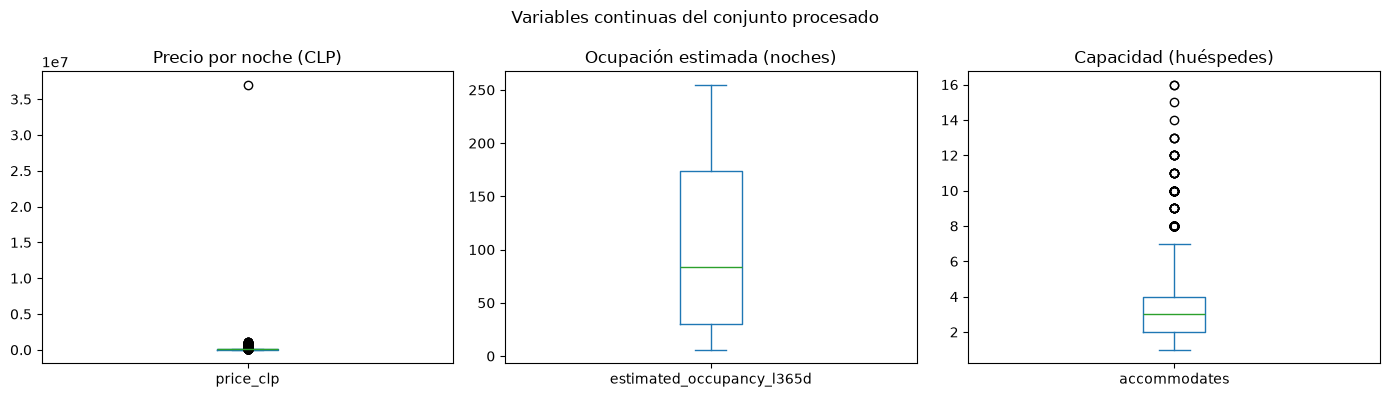

In [24]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, col, titulo in zip(
        ejes,
        ["price_clp", "estimated_occupancy_l365d", "accommodates"],
        ["Precio por noche (CLP)", "Ocupación estimada (noches)", "Capacidad (huéspedes)"]):
    df[col].plot.box(ax=eje)
    eje.set_title(titulo)
plt.suptitle("Variables continuas del conjunto procesado")
plt.tight_layout()
plt.show()

In [25]:
# Vista final: texto pasado a número, comodidades binarizadas y
# solo las columnas del análisis.
print("Dataset final:", df.shape)
df.head()

Dataset final: (3313, 64)


,id,host_id,neighbourhood_cleansed,latitude,longitude,property_type,propiedad_agrupada,room_type,accommodates,bedrooms,bedrooms_imputado,beds,...,last_review,antiguedad_dias,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,host_is_superhost,calculated_host_listings_count,es_multianfitrion
4,1226526,828029c6c29f,Providencia,-33.42681,-70.60961,Entire rental unit,Entire rental unit,Entire home/apt,4,2.0,0,2.0,...,2026-07-17,4820,4.67,4.74,4.83,4.91,4.92,4.94,4.72,t,2,1
5,1300359,250fdbee5201,Providencia,-33.43005,-70.61772,Entire rental unit,Entire rental unit,Entire home/apt,4,2.0,0,2.0,...,2026-08-30,4791,4.73,4.71,4.80,4.79,4.85,4.85,4.61,f,20,1
7,3735992,481459247d1a,Estación Central,-33.45593,-70.70020,Entire condo,Entire condo,Entire home/apt,5,2.0,0,5.0,...,2026-09-03,4238,4.71,4.81,4.69,4.76,4.90,4.28,4.62,t,9,1
8,3810101,9e622c2063be,Lo Barnechea,-33.35603,-70.24830,Entire rental unit,Entire rental unit,Entire home/apt,5,2.0,0,4.0,...,2026-09-11,4406,4.91,4.89,4.71,4.89,4.86,4.89,4.77,f,1,0
9,1446357,476b08a4a2a1,Lo Barnechea,-33.34869,-70.29280,Entire condo,Entire condo,Entire home/apt,6,2.0,0,6.0,...,2026-08-20,4771,4.68,4.64,4.51,4.67,4.89,4.83,4.42,f,1,0


## Conclusiones y trazabilidad

El *pipeline* dejó el conjunto sin datos personales, sin columnas vacías, con
el precio y los baños en formato numérico, las comodidades binarizadas y el
universo reducido a departamentos completos activos. Cada paso quedó
implementado como una función documentada y reutilizable (`cargar_datos`,
`eliminar_datos_personales`, `limpiar_precio`, `extraer_banos`,
`eliminar_columnas_sin_informacion`, `filtrar_universo`,
`imputar_mediana_por_grupo`, `agrupar_property_type`, `parsear_amenidades`,
`validar_dataset`), con un flujo modular, reproducible y verificable.

**Trazabilidad con el repositorio (F2):** este notebook está en la carpeta
`F2/` del repositorio; el resultado se guarda en `data/processed/` y el
diccionario observado en `docs/`. El historial de *commits* refleja el avance
del *pipeline* descrito en el informe técnico.

---

## 8. Recursividad: aplanar los metadatos del proyecto

Todo el procesamiento de arriba fue **estructurado**: secuencias,
condicionales y bucles. Esta sección mete la **recursividad**, que es la
herramienta natural cuando la estructura tiene una profundidad que no se
conoce de antemano.

El caso es real, no decorativo: los metadatos del proyecto forman un
diccionario anidado y, para exportarlos como tabla, hay que pasarlos a pares
clave-valor. Un bucle no sirve porque no se sabe cuántos niveles hay.

**Anatomía de la función recursiva:**
- *Caso base*: el valor no es un diccionario → se devuelve el par clave-valor.
- *Caso recursivo*: el valor es un diccionario → la función se llama a sí misma
  un nivel más abajo, arrastrando el prefijo de la ruta.

In [26]:
# Los metadatos del proyecto, con la estructura anidada que les corresponde
METADATOS = {
    "proyecto": {
        "nombre": "Alojamientos Airbnb en Santiago para decisión de inversión",
        "grupo": "Grupo 4",
        "fase": "F2",
        "semilla": SEMILLA,
    },
    "datos": {
        "archivo": "listings.csv (muestra estratificada)",
        "fuente": {
            "plataforma": "Inside Airbnb",
            "captura": "2026-09-25/26",
            "url": "http://insideairbnb.com/get-the-data/",
        },
    },
    "pipeline": {
        "anonimizacion": {"aplicada_en": "src/generar_muestra.py",
                          "verificada_en": "pipeline F2",
                          "columnas": COLUMNAS_PERSONALES,
                          "seudonimizado": "host_id"},
        "limpieza": {"precio": "texto a numerico",
                     "imputacion": {"beds": "mediana por tramo de accommodates",
                                    "bedrooms": "mediana por tramo de accommodates"},
                     "eliminadas": "columnas >= 90 % nulas"},
        "filtros": {"room_type": "Entire home/apt",
                    "activo": "reviews_ltm > 0 y availability_365 > 0"},
        "transformacion": {"property_type": "top 5 + Otro",
                           "amenities": f"top {TOP_AMENITIES} binarias"},
    },
}


def aplanar(estructura, prefijo="", separador="."):
    """Aplana un diccionario anidado en uno de un solo nivel.

    Ejemplo
    -------
    >>> aplanar({"a": {"b": 1, "c": {"d": 2}}})
    {'a.b': 1, 'a.c.d': 2}
    """
    plano = {}
    for clave, valor in estructura.items():
        # Se arma la ruta completa: en el primer nivel no hay prefijo
        ruta = f"{prefijo}{separador}{clave}" if prefijo else str(clave)

        if isinstance(valor, dict):
            # CASO RECURSIVO: la función se llama a si misma un nivel mas abajo
            plano.update(aplanar(valor, ruta, separador))
        elif isinstance(valor, (list, tuple)):
            # Las secuencias se convierten en texto legible para la tabla
            plano[ruta] = ", ".join(str(v) for v in valor)
        else:
            # CASO BASE: el valor es simple, se devuelve el par
            plano[ruta] = valor
    return plano


metadatos_planos = aplanar(METADATOS)
print(f"El diccionario anidado se aplanó en {len(metadatos_planos)} pares.\n")
for clave, valor in metadatos_planos.items():
    print(f"  {clave:<52} {str(valor)[:60]}")

El diccionario anidado se aplanó en 20 pares.

  proyecto.nombre                                      Alojamientos Airbnb en Santiago para decisión de inversión
  proyecto.grupo                                       Grupo 4
  proyecto.fase                                        F2
  proyecto.semilla                                     42
  datos.archivo                                        listings.csv (muestra estratificada)
  datos.fuente.plataforma                              Inside Airbnb
  datos.fuente.captura                                 2026-09-25/26
  datos.fuente.url                                     http://insideairbnb.com/get-the-data/
  pipeline.anonimizacion.aplicada_en                   src/generar_muestra.py
  pipeline.anonimizacion.verificada_en                 pipeline F2
  pipeline.anonimizacion.columnas                      name, description, host_name, host_about, host_location, hos
  pipeline.anonimizacion.seudonimizado                 host_id
  pipeline.li

In [27]:
# Verificación de la función recursiva: casos normal, profundo y limite
assert aplanar({"a": 1}) == {"a": 1}, "Caso plano"
assert aplanar({"a": {"b": 1}}) == {"a.b": 1}, "Un nivel de anidamiento"
assert aplanar({"a": {"b": {"c": {"d": 4}}}}) == {"a.b.c.d": 4}, "Anidamiento profundo"
assert aplanar({}) == {}, "Caso límite: diccionario vacío"
assert aplanar({"x": [1, 2, 3]}) == {"x": "1, 2, 3"}, "Listas convertidas a texto"
print("[OK] La función recursiva pasa las cinco pruebas.")

[OK] La función recursiva pasa las cinco pruebas.


> **Cuándo NO usar recursividad.** Si la profundidad se conoce y es fija,
> un bucle anidado es mas claro y mas rápido. La recursividad se justifica
> cuando la profundidad varía, como acá. Python además limita la profundidad a
> unos mil niveles, así que no reemplaza un bucle sobre miles de filas.

---

## 9. Persistencia y trazabilidad

El resultado tiene que quedar guardado y documentado. Esta sección produce
los artefactos que se versionan en el repositorio y se citan en el informe.

In [28]:
ARCHIVO_PROCESADO = DIR_PROCESADO / "listings_procesado.csv"

# index=False evita que quede una columna con el número de fila, que no es un dato
df.to_csv(ARCHIVO_PROCESADO, index=False)

# Verificación de ida y vuelta: se relee lo que se guardó y se comprueba que
# coincida. Si el archivo se escribió mal, mejor descubrirlo ahora.
releido = pd.read_csv(ARCHIVO_PROCESADO)
assert releido.shape == df.shape, "El archivo releído no coincide en dimensiones"
print(f"Guardado y verificado: {ARCHIVO_PROCESADO.relative_to(RAIZ)}")
print(f"Tamaño en disco: {ARCHIVO_PROCESADO.stat().st_size / 1024:.0f} kB")
print(f"Columnas con datos personales en el archivo: "
      f"{[c for c in COLUMNAS_PERSONALES if c in releido.columns] or 'ninguna'}")

# Los metadatos aplanados con la función recursiva de la sección 8
pd.DataFrame(list(metadatos_planos.items()), columns=["clave", "valor"]).to_csv(
    DIR_DOCS / "metadatos_proyecto.csv", index=False)
print(f"Metadatos exportados a {DIR_DOCS.relative_to(RAIZ)}/metadatos_proyecto.csv")

Guardado y verificado: data/processed/listings_procesado.csv
Tamaño en disco: 1044 kB
Columnas con datos personales en el archivo: ninguna
Metadatos exportados a docs/metadatos_proyecto.csv


In [29]:
# Resumen entre el punto de partida y el resultado.
# Esta tabla responde de una la pregunta "qué cambió".
resumen = pd.DataFrame([
    {"indicador": "Filas", "inicial": df_crudo.shape[0], "final": df.shape[0]},
    {"indicador": "Columnas", "inicial": df_crudo.shape[1], "final": df.shape[1]},
    {"indicador": "Valores nulos",
     "inicial": int(df_crudo.isna().sum().sum()), "final": int(df.isna().sum().sum())},
    {"indicador": "Columnas personales en data/raw",
     "inicial": len([c for c in COLUMNAS_PERSONALES if c in df_crudo.columns]),
     "final": 0},
    {"indicador": "Filas duplicadas",
     "inicial": int(df_crudo.duplicated().sum()), "final": int(df.duplicated().sum())},
])
resumen

,indicador,inicial,final
0,Filas,5106,3313
1,Columnas,78,64
2,Valores nulos,85374,0
3,Columnas personales en data/raw,0,0
4,Filas duplicadas,0,0


---

## 10. Reflexión técnica

### Hallazgos

- **Las 13 columnas vacías y las casi vacías no aportaban nada.** `bathrooms`,
  `neighbourhood`, `host_since` e `instant_bookable` llegaron 100 % nulas;
  `license` al 99 % y `source` al 95 %. Eliminarlas achicó el conjunto sin
  perder información, y explica por qué los baños se sacaron de
  `bathrooms_text`.

- **El precio era texto con formato monetario.** `"$59,303.00"` pedía una
  conversión explícita; el 4,7 % de filas sin precio se resolvió dentro del
  universo eliminando una fracción pequeña, justificada porque el precio es
  variable de resultado y no se fabrica.

- **La ocupación estimada llega con el sesgo incorporado.** Cerca de un 13 %
  del universo está en el tope de 255 noches: la bandera `ocupacion_tope`
  guarda esa información para la Fase 3 en vez de esconderla.

- **Las comodidades son el campo mas desordenado.** 1.793 valores distintos en
  la muestra, con variantes del mismo servicio. Binarizar las 20 mas
  frecuentes conserva lo que importa para la pregunta 3 sin inflar el
  conjunto.

### Dificultades y cómo se resolvieron

- **Datos personales en el archivo original.** Se eliminan al generar la
  muestra (`src/generar_muestra.py`, D5), que es lo que permite versionar
  `data/raw/`, y el pipeline verifica la misma regla al cargar por si el
  archivo cambiara. `host_id` queda seudonimizado con el hash del módulo de la
  Fase 1: el conteo de anuncios por anfitrión sigue siendo posible.

- **`beds` con 32 faltantes dentro del universo.** Comparamos cuatro
  estrategias de imputación con cifras y elegimos la mediana por tramo de
  capacidad, la que menos deforma la dispersión.

### Decisiones que quedan abiertas

- Si las variantes de comodidades (`"TV"` vs. `"TV with standard cable"`)
  conviene consolidarlas antes de comparar frecuencias en la Fase 3.
- Si el idioma de las reseñas (D6) aporta como aproximación a la demanda
  extranjera, mirando su costo de procesamiento.
- Si los valores extremos de camas y dormitorios (legítimos pero raros) deben
  tratarse distinto en los indicadores por configuración.

> **Declarar lo que queda abierto evidencia mas dominio que presentar todo
> resuelto.** Y en esta fase no debería estarlo.

---

## 11. Verificación antes de entregar

**Notebook**

- Corre completo tras *Kernel → Restart Kernel and Run All Cells*, sin errores.
- La numeración de ejecución queda continua.
- Cada bloque de código va precedido de una celda narrativa que explica su lógica.
- Todas las rutas son relativas y la semilla quedó declarada.

**Contenido técnico**

- La procedencia del conjunto está documentada, con enlace y cita en APA 7.
- Los datos personales se eliminaron al cargar y el archivo procesado no los tiene.
- El diccionario de variables declara y observa el rol de cada columna.
- Las decisiones de filtrado, imputación y transformación quedaron
  **justificadas con cifras**.
- Hay pruebas de casos normales, límite y excepciones.

**Archivos**

- `data/raw/` conserva la muestra original sin modificar.
- `data/processed/` tiene el conjunto procesado, anonimizado.
- `docs/` tiene el diccionario observado y los metadatos del pipeline.

**Repositorio**

- Carpeta F2 con este notebook, commits de todos los integrantes y README
  actualizado.

---

*Cuaderno de la Fase 2 · MCDI500 · Magíster en Ciencia de Datos e Inteligencia
Artificial · Universidad Andrés Bello*